# 05 – Mô hình dựa trên cây: Random Forest

1. Random Forest với tham số mặc định – chẩn đoán overfitting.
2. Random Forest có điều chuẩn (giới hạn độ phức tạp cây).
3. Độ quan trọng đặc trưng (MDI) và cảnh báo về biến đối chứng `rv1`.

(Gradient Boosting và tinh chỉnh siêu tham số: phần sau của notebook.)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

from src.config import RANDOM_STATE
from src.data_loader import load_raw_data
from src.features import make_xy
from src.preprocessing import make_pipeline
from src.split import time_split
from src.train import cv_evaluate, fit_and_validate
from src.visualization import save_fig, set_style

set_style()
train, val, test = time_split(load_raw_data())
X_tr, y_tr = make_xy(train)
X_va, y_va = make_xy(val)
cols = list(X_tr.columns)
SHOW = ["train_RMSE", "train_R2", "cv_RMSE", "cv_RMSE_std", "cv_R2", "val_RMSE", "val_MAE", "val_R2"]

## 1. Random Forest mặc định
100 cây, không giới hạn độ sâu (`max_depth=None`), `min_samples_leaf=1` → mỗi cây mọc tới khi lá chỉ còn 1 mẫu.

In [2]:
rf_default = make_pipeline(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                           cols, kind="tree")
rf_results = {}
rf_default_fit, r = fit_and_validate(rf_default, X_tr, y_tr, X_va, y_va)
r.update(cv_evaluate(rf_default, X_tr, y_tr))
rf_results["RF mặc định"] = r
pd.DataFrame(rf_results).T[SHOW].round(3)

,train_RMSE,train_R2,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
RF mặc định,26.281,0.947,117.96,13.919,-0.363,103.464,69.056,-0.258


**Overfitting rất nặng:**
- Trên train: R² ≈ 0,95, RMSE ≈ 25 Wh – gần như "thuộc lòng" dữ liệu.
- Trên validation: R² **âm** (≈ −0,26), RMSE ≈ 103 Wh – **kém hơn cả baseline trung bình** (92,4 Wh).
- CV theo thời gian cũng cho R² âm → không phải do may rủi của một lần chia.

Nguyên nhân: cây sâu học cả **nhiễu** và các đỉnh tiêu thụ ngẫu nhiên gắn với điều kiện cảm biến cụ thể của mùa
đông; sang tháng 4–5, các tổ hợp nhiệt độ/độ ẩm đó không còn lặp lại nên dự đoán lệch xa. Bài báo gốc cũng
ghi nhận khoảng cách train–test lớn (R² 0,97 → 0,57) dù dùng cách chia dễ hơn.

## 2. Random Forest có điều chuẩn
Giới hạn độ phức tạp để giảm phương sai:
- `min_samples_leaf`: mỗi lá phải có ít nhất k mẫu → dự đoán là trung bình của nhiều mẫu, mượt hơn.
- `max_features`: mỗi lần tách chỉ xét 1/3 số đặc trưng → các cây đa dạng hơn, giảm tương quan giữa cây.
- `max_depth`: giới hạn độ sâu.

In [3]:
configs = {
    "RF max_depth=8": dict(max_depth=8),
    "RF leaf=20, max_features=0.33": dict(min_samples_leaf=20, max_features=0.33),
    "RF leaf=50, max_features=0.33": dict(min_samples_leaf=50, max_features=0.33),
}
for name, kw in configs.items():
    pipe = make_pipeline(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **kw),
                         cols, kind="tree")
    _, r = fit_and_validate(pipe, X_tr, y_tr, X_va, y_va)
    r.update(cv_evaluate(pipe, X_tr, y_tr))
    rf_results[name] = r
rf_table = pd.DataFrame(rf_results).T[SHOW].round(3)
rf_table

,train_RMSE,train_R2,cv_RMSE,cv_RMSE_std,cv_R2,val_RMSE,val_MAE,val_R2
RF mặc định,26.281,0.947,117.960,13.919,-0.363,103.464,69.056,-0.258
RF max_depth=8,65.974,0.653,108.925,17.074,-0.168,92.544,54.393,-0.007
"RF leaf=20, max_features=0.33",76.996,0.544,95.182,5.365,0.131,84.929,47.718,0.152
"RF leaf=50, max_features=0.33",86.883,0.419,94.031,4.706,0.153,84.680,46.652,0.157


Đã lưu hình: reports/figures/05_rf_overfitting.png


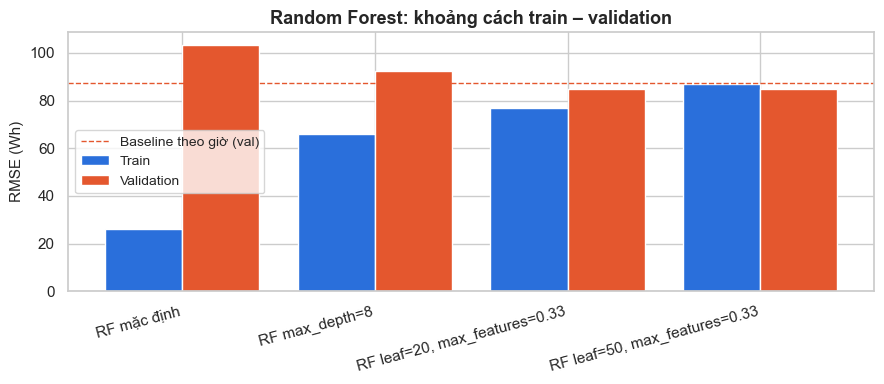

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(rf_table))
ax.bar(x - 0.2, rf_table["train_RMSE"], width=0.4, label="Train")
ax.bar(x + 0.2, rf_table["val_RMSE"], width=0.4, label="Validation")
ax.axhline(87.23, color="#e4572e", linestyle="--", linewidth=1, label="Baseline theo giờ (val)")
ax.set_xticks(x)
ax.set_xticklabels(rf_table.index, rotation=15, ha="right")
ax.set_ylabel("RMSE (Wh)")
ax.set_title("Random Forest: khoảng cách train – validation")
ax.legend()
fig.tight_layout()
save_fig(fig, "05_rf_overfitting")
plt.show()

**Nhận xét:**
- Điều chuẩn **thu hẹp mạnh khoảng cách train–validation**: R² train giảm từ 0,95 xuống ~0,4–0,65 nhưng R²
  validation tăng từ −0,26 lên ~0,15 (RMSE ≈ 84,7 Wh với `min_samples_leaf=50`).
- Chỉ giới hạn `max_depth=8` chưa đủ (R² validation ≈ 0); kết hợp `min_samples_leaf` + `max_features` hiệu quả hơn.
- Random Forest có điều chuẩn ngang với Lasso (~85 Wh) và nhỉnh hơn baseline theo giờ – **lợi thế phi tuyến
  chưa lớn** khi chỉ dùng dữ liệu cảm biến + thời tiết. Phần tinh chỉnh siêu tham số và Gradient Boosting sẽ
  kiểm chứng tiếp.